In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

df = pd.read_parquet("../data/processed/accepted_clean.parquet")
train = df[(df["issue_d"] >= "2012-01-01") & (df["issue_d"] < "2015-01-01")]
test  = df[(df["issue_d"] >= "2015-01-01") & (df["issue_d"] < "2016-01-01")]

feats = [c for c in df.columns if c not in ["issue_d", "target", "term", "installment"]]
cat_vars = ["home_ownership", "verification_status", "purpose",
            "addr_state", "application_type"]

def prep(d):
    X = d[feats].copy()
    for c in cat_vars:
        # Same category list for train and test so the codes match
        X[c] = pd.Categorical(X[c], categories=sorted(df[c].dropna().unique()))
    return X

gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1,
                                    categorical_features="from_dtype", random_state=42)
gb.fit(prep(train), train["target"])
auc_gb = roc_auc_score(test["target"], gb.predict_proba(prep(test))[:, 1])
print(f"Gradient boosting test AUC: {auc_gb:.3f}   (scorecard: 0.654)")

Gradient boosting test AUC: 0.670   (scorecard: 0.654)


Background dataset has 306462 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=306462 when initializing the masker.


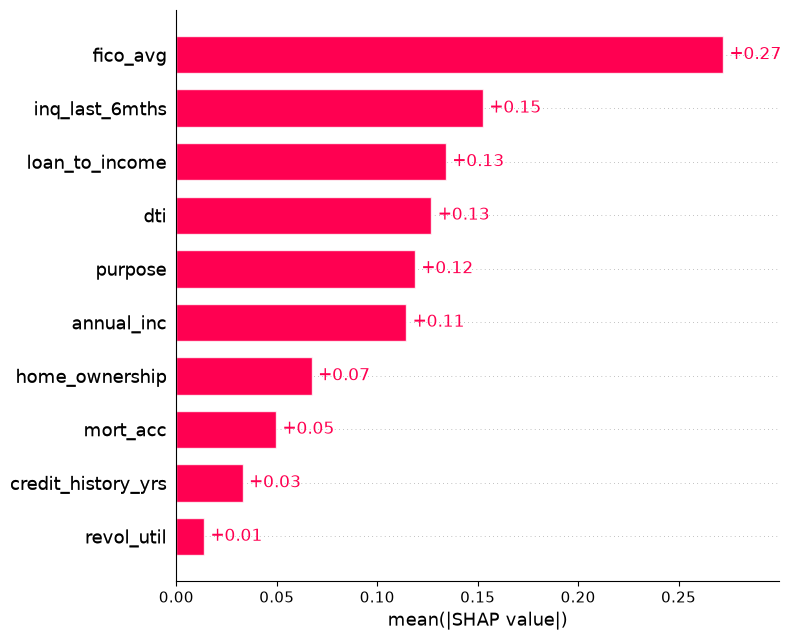

In [2]:
import os
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

train_w = pd.read_parquet("../data/processed/train_woe.parquet")
test_w  = pd.read_parquet("../data/processed/test_woe.parquet")
X_train_w, y_train = train_w.drop(columns="target"), train_w["target"]
X_test_w,  y_test  = test_w.drop(columns="target"),  test_w["target"]

# Same model as in notebook 04
model = LogisticRegression(C=10, max_iter=1000).fit(X_train_w, y_train)
p_test = model.predict_proba(X_test_w)[:, 1]

# Explain a random sample of 2015 loans
sample = X_test_w.sample(5000, random_state=42)
explainer = shap.LinearExplainer(model, X_train_w)
sv = explainer(sample)

os.makedirs("../reports/figures", exist_ok=True)
shap.plots.bar(sv, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
grp = pd.read_parquet("../data/processed/accepted_clean.parquet",
                      columns=["issue_d", "home_ownership", "annual_inc"])
grp = grp[(grp["issue_d"] >= "2015-01-01") &
          (grp["issue_d"] < "2016-01-01")].reset_index(drop=True)
assert len(grp) == len(p_test), "row count mismatch"

grp["pd"] = p_test
grp["bad"] = y_test.values
grp["income_band"] = pd.qcut(grp["annual_inc"], 4,
                             labels=["Q1 low", "Q2", "Q3", "Q4 high"])

def group_report(col):
    rows = {}
    for name, g in grp.groupby(col, observed=True):
        rows[name] = {
            "n": len(g),
            "avg_pd": g["pd"].mean(),
            "bad_rate": g["bad"].mean(),
            # AUC is only defined when both classes are present
            "auc": roc_auc_score(g["bad"], g["pd"]) if g["bad"].nunique() > 1 else np.nan,
        }
    return pd.DataFrame(rows).T.round(3)

display(group_report("income_band"))
display(group_report("home_ownership"))

,n,avg_pd,bad_rate,auc
Q1 low,71792.0,0.179,0.191,0.613
Q2,71645.0,0.140,0.156,0.638
Q3,72960.0,0.115,0.136,0.657
Q4 high,66627.0,0.088,0.110,0.669


,n,avg_pd,bad_rate,auc
ANY,1.0,0.072,0.000,NaN
MORTGAGE,129762.0,0.107,0.121,0.659
OWN,31800.0,0.140,0.158,0.631
RENT,121463.0,0.154,0.177,0.631
